<a href="https://colab.research.google.com/github/dottomalongo3/COU07506-Week01-24034496875/blob/main/COU07506_Week01_%3C24034496875.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Task 1.1 —my first notebook
week01,
NAMES:DOTTO MALONGO MASHAURI,
Registration: 24034496875
group. 07


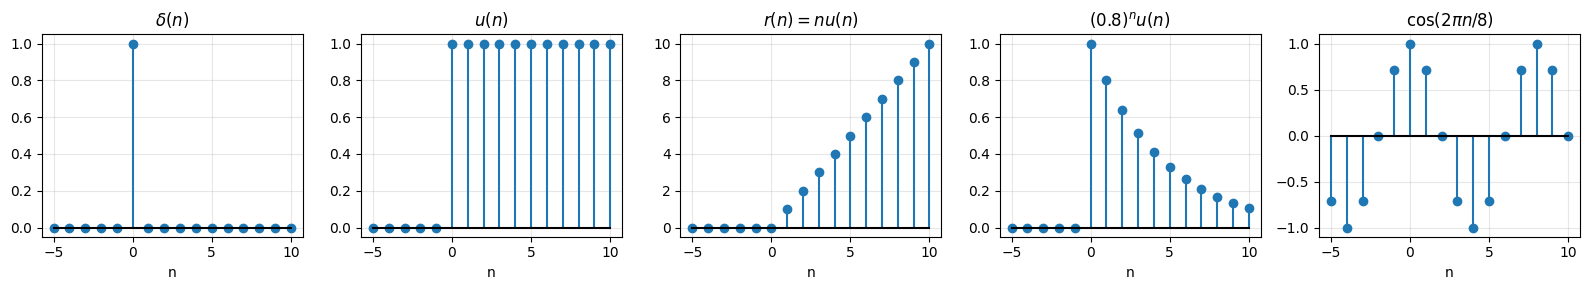

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

n = np.arange(-5, 11)

delta = (n == 0).astype(float)       # unit impulse
step = (n >= 0).astype(float)        # unit step
ramp = n * step                      # unit ramp
expo = 0.8**n * step                 # exponential
cosine = np.cos(2 * np.pi * n / 8)   # cosine

signals = [delta, step, ramp, expo, cosine]
titles = [
    r"$\delta(n)$",
    r"$u(n)$",
    r"$r(n)=nu(n)$",
    r"$(0.8)^n u(n)$",
    r"$\cos(2\pi n/8)$"
]

fig, axes = plt.subplots(1, 5, figsize=(16, 3))

for ax, x, title in zip(axes, signals, titles):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("n")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Task 1.2 — Change the parameters


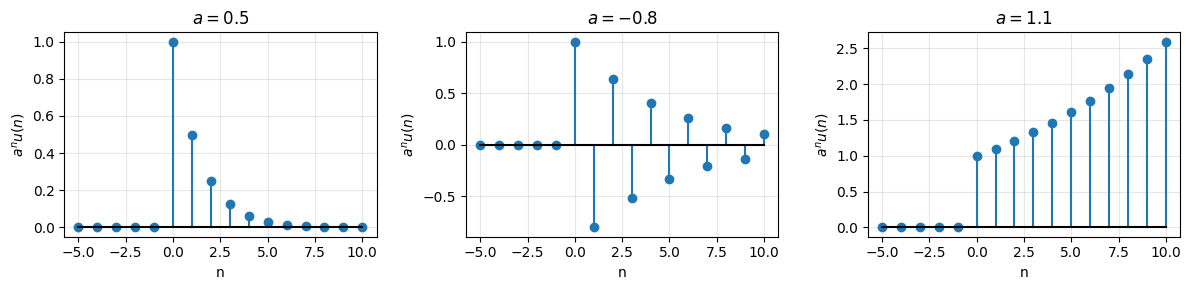

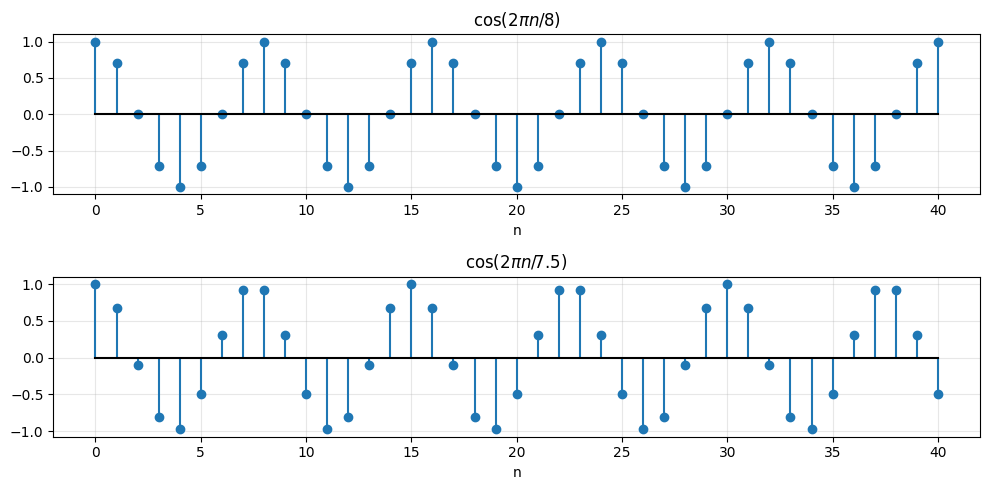

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# (a)^n u(n) kwa a = 0.5, -0.8, na 1.1
n1 = np.arange(-5, 11)
u = (n1 >= 0).astype(float)
a_values = [0.5, -0.8, 1.1]

fig, axes = plt.subplots(1, 3, figsize=(12, 3))

for ax, a in zip(axes, a_values):
    x = (a ** n1) * u
    ax.stem(n1, x, basefmt="k-")
    ax.set_title(f"$a={a}$")
    ax.set_xlabel("n")
    ax.set_ylabel(r"$a^n u(n)$")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# Cosine signals kwa 0 <= n <= 40
n2 = np.arange(0, 41)
x1 = np.cos(2 * np.pi * n2 / 8)
x2 = np.cos(2 * np.pi * n2 / 7.5)

fig, axes = plt.subplots(2, 1, figsize=(10, 5))

axes[0].stem(n2, x1, basefmt="k-")
axes[0].set_title(r"$\cos(2\pi n/8)$")
axes[0].set_xlabel("n")
axes[0].grid(True, alpha=0.3)

axes[1].stem(n2, x2, basefmt="k-")
axes[1].set_title(r"$\cos(2\pi n/7.5)$")
axes[1].set_xlabel("n")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Task 1.3 — Working with audio


/tmp/ipykernel_906/2987218398.py:15: UserWarning: PySoundFile failed. Trying audioread instead.
  x, fs = librosa.load(fname, sr=None, mono=True)
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


File: my recording.wav.m4a
Sample rate: 48000 Hz
Duration: 5.12 seconds
Samples: 245760


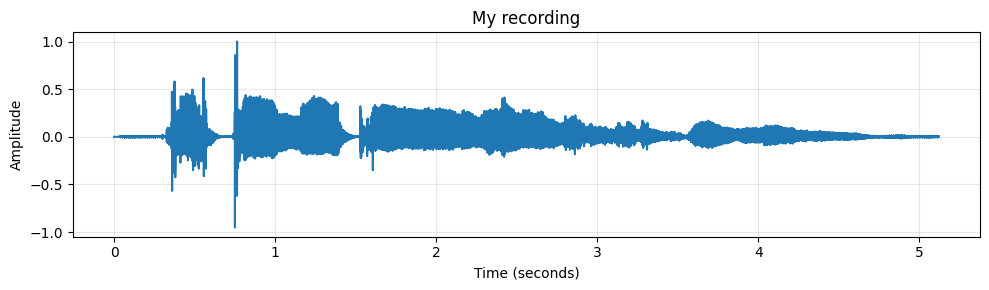

In [ ]:
!pip -q install librosa

import os
import numpy as np
import matplotlib.pyplot as plt
import librosa
from IPython.display import Audio, display

fname = "my recording.wav.m4a"  # Exact filename shown in the Files panel

if not os.path.exists(fname):
    raise FileNotFoundError(f"File not found: {fname}")

# Load the recording as mono audio
x, fs = librosa.load(fname, sr=None, mono=True)

# Normalize for playback and plotting
peak = np.max(np.abs(x))
if peak > 0:
    x = x / peak

t = np.arange(len(x)) / fs

print(f"File: {fname}")
print(f"Sample rate: {fs} Hz")
print(f"Duration: {len(x) / fs:.2f} seconds")
print(f"Samples: {len(x)}")

plt.figure(figsize=(10, 3))
plt.plot(t, x)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("My recording")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

display(Audio(x, rate=fs))

Analysis Questions
1. What is the recording’s sampling rate, and how many numbers are needed for one minute of mono audio?
   Answer
   A sampling rate is 48,000 Hz. That means the audio has 48,000 samples per second. For one minute:
   \[
   48{,}000 \times 60 = 2{,}880{,}000
   \]
   So, one minute of mono audio requires 2,880,000 sample values.
2. Why is a stem plot more appropriate than a continuous line for \(x(n)\)?
   \(x(n)\) is a discrete-time signal, with values defined at integer sample positions \(n\). A stem plot shows each sample separately. A continuous line can imply that the signal is defined at points between samples.
3. For \(a=1.1\), which system property would the exponential violate if it were an impulse response?
   It would violate BIBO stability. A discrete-time LTI system is BIBO stable only if the absolute values of its impulse response have a finite sum. The sequence \((1.1)^n u(n)\) grows as \(n\) increases, so its sum is infinite. A system with this impulse response would therefore be unstable.